# Iterated Prisoner's Dilemma: Comparing Strategies

Two players each choose to **cooperate** (stay mum) or **defect** (snitch). Whatever the other does, defecting
pays more, yet two defectors do worse than two cooperators:

| | opponent cooperates | opponent defects |
|---|---|---|
| **I cooperate** | 3 (reward) | 0 (sucker) |
| **I defect** | 5 (temptation) | 1 (punishment) |

Played once, defection wins. Played 200 times against the same opponent, a strategy can reward cooperation and
punish defection, and the picture changes. This notebook plays every strategy against every other (Axelrod's
round robin) and asks which score best, and how that changes when players make mistakes.

The seven strategies come from a 2008 experiment; five classics are added for comparison. The population
version of the experiment, where successful strategies multiply, is in `population-dynamics.ipynb`.

**Running it.** The whole notebook runs in about 5 seconds. The code lives in the `prisoners_dilemma` package
next to this folder: `strategies` (the rules), `game` (payoffs and matches), `tournament` (the tables below).
To try a strategy of your own, write a function `move(view, rng)` that returns a bool array (True = cooperate)
from a `strategies.View` (the round number, both players' last moves and the opponent's counts of cooperations
and defections, one entry per match), wrap it in `strategies.Strategy(name, description, move)`, and pass it in
the list given to `tournament.head_to_head` alongside the names.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # project root, so prisoners_dilemma imports without installing
from prisoners_dilemma import plotting, strategies, tournament

plotting.style()
ALL = list(strategies.STRATEGIES)
ROUNDS, REPEATS = 200, 200

## The strategies

In [2]:
pd.set_option("display.max_colwidth", None)
pd.DataFrame([{"strategy": s.name, "2008": s in strategies.ORIGINAL, "random": s.random,
               "rule": s.description} for s in strategies.STRATEGIES.values()]).set_index("strategy")

,2008,random,rule
strategy,,,
Random,True,True,flips a fair coin every move
T4T,True,False,"tit for tat: cooperates first, then copies the opponent's last move"
AvgT4T,True,False,"cooperates first, then cooperates while the opponent has cooperated more often than defected"
Pred1,True,False,"cooperates first, then exploits an opponent who cooperates more than 1.1x as often as they defect, and retaliates against one who cooperates less than 0.4x as often"
Defect,True,False,always defects
T4TDefect,True,True,"tit for tat, but defects at random 4% of the time"
T4TForgive,True,True,"tit for tat, but forgives a defection 3% of the time"
Cooperate,False,False,always cooperates
Grudger,False,False,"cooperates until the opponent defects once, then always defects"


## Head to head

Every pair plays 200 matches of 200 moves (one match when neither side is random, since the result
cannot change). Each cell is the row strategy's mean points per match against the column strategy. Mutual
cooperation for 200 moves is worth 600; mutual defection 200.

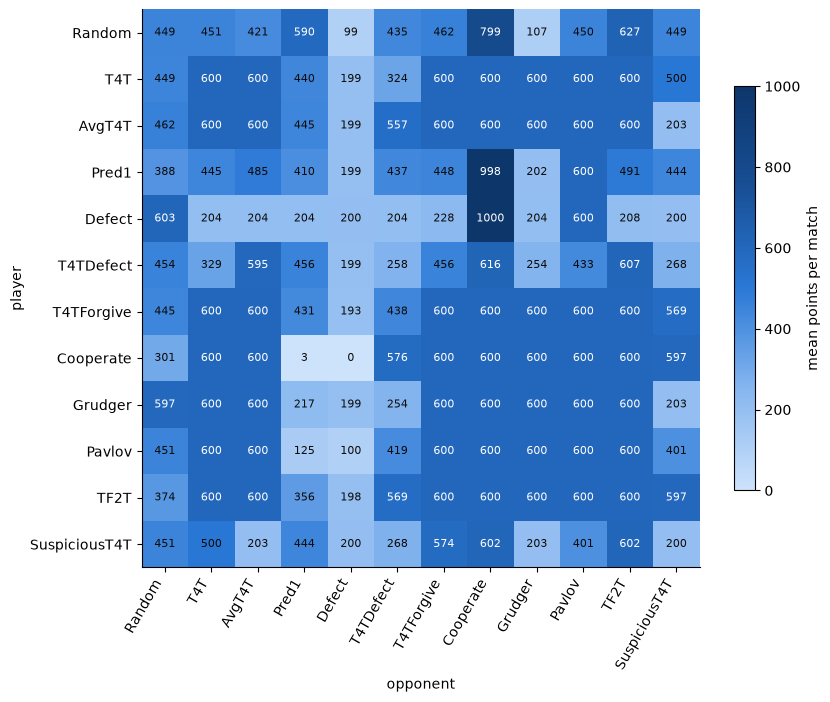

In [3]:
results = tournament.head_to_head(ALL, ROUNDS, REPEATS, rng=0)
matrix = tournament.score_matrix(results)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(matrix, cmap=plotting.BLUES, vmin=0, vmax=1000)
ax.set_xticks(range(len(ALL)), ALL, rotation=60, ha="right")
ax.set_yticks(range(len(ALL)), ALL)
ax.grid(False)
for i in range(len(ALL)):
    for j in range(len(ALL)):
        v = matrix.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 520 else "#0b0b0b")
ax.set_xlabel("opponent")
ax.set_ylabel("player")
fig.colorbar(im, ax=ax, shrink=0.7, label="mean points per match")
plt.show()

Reading across a row:

- **Defect** takes 1000 from Cooperate and about 600 from Random and Pavlov (Pavlov cooperates every other
  move against it), but against anything that retaliates it gets 200 to 230: one or two exploited moves, then
  mutual punishment.
- **Pred1** exploits the unconditional cooperator just as hard (998), and only manages that against Cooperate.
- The **tit-for-tat family** (T4T, AvgT4T, T4TForgive, TF2T, Grudger) score 600 against each other and against
  every other nice strategy, and lose only a few points to Defect.
- **T4TDefect**, tit for tat with a random 4% defection, starts echoing feuds with T4T (about 330 each way): one
  random defection is answered, and the answer is answered, until the next random defection breaks the cycle.
  Against T4TForgive the feuds are cut short by its 3% forgiveness, and both sides score more (about 440 and
  460).
- **SuspiciousT4T** opens with a defection and gets locked into alternation with T4T (500) or mutual defection
  with AvgT4T and Grudger (about 200).

## Ranking: scoring is not winning

Ranked by mean points over all opponents (self included). The `win` column is the fraction of opponents a
strategy beats outright in a match.

In [4]:
rank = tournament.ranking(results)
rank.round(3)

,score,win,loss,tie,coop
player,,,,,
TF2T,524.489,0.000,0.417,0.583,0.856
T4TForgive,523.052,0.000,0.411,0.589,0.787
T4T,509.299,0.000,0.290,0.710,0.732
AvgT4T,505.472,0.049,0.285,0.667,0.748
Pavlov,474.692,0.039,0.284,0.677,0.774
Cooperate,473.051,0.000,0.417,0.583,1.000
Grudger,472.511,0.167,0.087,0.747,0.597
Pred1,462.203,0.524,0.308,0.168,0.359
Random,444.970,0.466,0.442,0.092,0.500


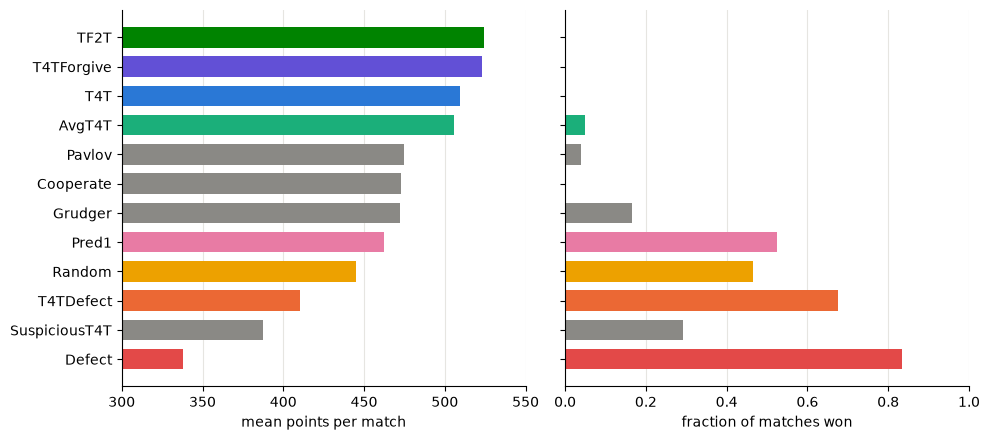

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
order = rank.index[::-1]
colors = [plotting.color(n) for n in order]
ax1.barh(order, rank.loc[order, "score"], color=colors, height=0.7)
ax1.set_xlabel("mean points per match")
ax1.set_xlim(300, 550)
ax2.barh(order, rank.loc[order, "win"], color=colors, height=0.7)
ax2.set_xlabel("fraction of matches won")
ax2.set_xlim(0, 1)
for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

The two axes run against each other. Defect never loses a match (it cannot be out-scored on any single
move), yet it finishes last; tit for tat never wins a match, yet it finishes near the top. A match is not
zero-sum: what matters is how many points a strategy collects across all its opponents, and cooperators collect
600 from each other while defectors collect about 200.

Without mistakes, the most forgiving retaliators (TF2T, T4TForgive) come first, followed closely by T4T and
AvgT4T. The predatory and noisy strategies (Pred1, Random, T4TDefect, SuspiciousT4T) sit below the plain
cooperator.

## When players make mistakes

With noise, each intended move is flipped with a small probability. A single mistake between two tit-for-tat
players starts an echo of retaliation that lasts until another mistake ends it, so strict retaliation becomes
expensive.

The full round robin again at each noise level; each cell is a strategy's mean points per match over all
opponents.

In [6]:
noise_levels = [0, 0.005, 0.01, 0.02, 0.05, 0.1]
by_noise = pd.DataFrame({e: tournament.ranking(tournament.head_to_head(ALL, ROUNDS, REPEATS, noise=e, rng=1))["score"]
                         for e in noise_levels}).T.rename_axis("noise")
by_noise.round(0)

player,AvgT4T,Cooperate,Defect,Grudger,Pavlov,Pred1,Random,SuspiciousT4T,T4T,T4TDefect,T4TForgive,TF2T
noise,,,,,,,,,,,,
0.000,506.0,473.0,338.0,472.0,475.0,463.0,446.0,388.0,509.0,411.0,522.0,525.0
0.005,479.0,437.0,341.0,417.0,448.0,461.0,442.0,404.0,471.0,422.0,491.0,500.0
0.010,472.0,420.0,345.0,399.0,433.0,459.0,442.0,411.0,461.0,429.0,478.0,490.0
0.020,464.0,409.0,351.0,384.0,424.0,458.0,443.0,415.0,454.0,436.0,465.0,479.0
0.050,454.0,400.0,370.0,382.0,424.0,453.0,443.0,419.0,450.0,444.0,453.0,465.0
0.100,447.0,397.0,396.0,401.0,426.0,451.0,443.0,425.0,447.0,447.0,449.0,449.0


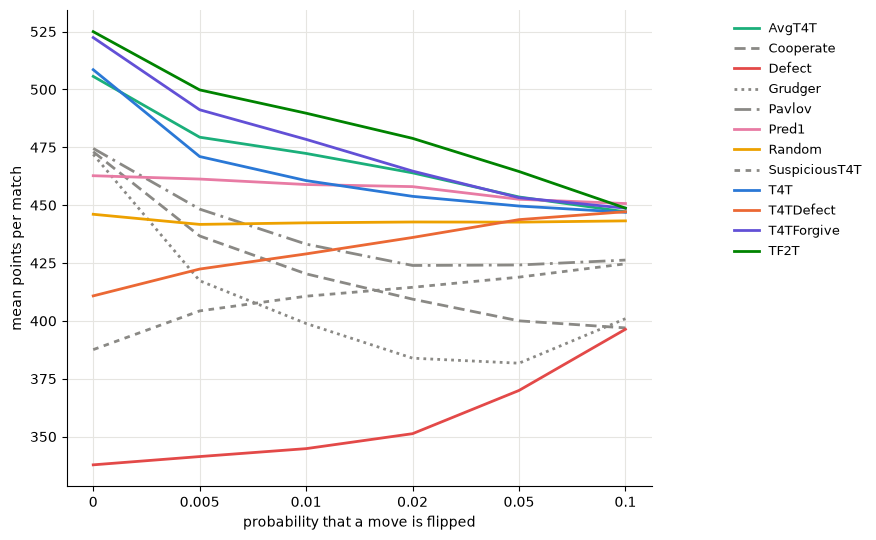

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))
spaced = by_noise.reset_index(drop=True)  # noise levels evenly spaced on the x axis
plotting.plot_lines(spaced, ax)
ax.set_xticks(spaced.index, [f"{e:g}" for e in noise_levels])
ax.set_xlabel("probability that a move is flipped")
ax.set_ylabel("mean points per match")
plt.tight_layout()
plt.show()

The same scores as ranks (1 = best), one column per noise level, sorted by rank at 5% noise:

In [8]:
by_noise.rank(axis=1, ascending=False).astype(int).T.sort_values(0.05)

noise,0.000,0.005,0.010,0.020,0.050,0.100
player,,,,,,
TF2T,1,1,1,1,1,2
AvgT4T,4,3,3,3,2,5
T4TForgive,2,2,2,2,3,3
Pred1,8,5,5,4,4,1
T4T,3,4,4,5,5,6
T4TDefect,10,9,8,7,6,4
Random,9,7,6,6,7,7
Pavlov,5,6,7,8,8,8
SuspiciousT4T,11,11,10,9,9,9


- Half a percent of noise already costs every retaliator. T4T falls from 509 to 471 points and from 3rd to
  5th place by 2% noise; **Grudger** falls from 7th to 11th, since one accidental defection ends cooperation for
  the rest of the match.
- **TF2T**, which retaliates only after two defections in a row, ignores isolated mistakes and keeps first
  place up to 5% noise, opening a lead of about 15 points over the next strategy.
- **Pavlov** (win-stay, lose-shift) recovers from mutual mistakes against itself, but Defect and the random
  strategies exploit it; it slides from 5th to 8th.
- **Cooperate** suffers as soon as there is noise: other players' mistaken defections turn the retaliators
  against it, and it never answers back.
- **Random** hardly notices noise (flipping a coin flip changes nothing), and with T4TDefect, which is already
  noisy, it climbs the table as the others fall.
- At 10% noise everyone's moves are partly random, the strategies bunch within a few points, and Pred1, which
  exploits opponents who cooperate too much, comes first. Defect stays last at every noise level.

Rankings depend on the mix of opponents. The next notebook lets the mix change: strategies that score well
multiply.